<!-- project-navigation -->
# 17_Model_Evaluation
Role: Final LightGBM evaluation.

See [notebook guide](README.md) and [model comparison](../reports/model_comparison.md). Historical code and outputs are retained; run with the project root as working directory.


In [1]:
# ============================================================
# 17_Model_Evaluation.ipynb
# ÉVALUATION FINALE DU MODÈLE LIGHTGBM
# ============================================================

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

print("✓ Librairies importées")

✓ Librairies importées


In [4]:
# ============================================================
# CHARGEMENT DU MODÈLE ET DES DONNÉES
# ============================================================

model_lgb_spw = joblib.load(
    "data/models/lightgbm_scale_pos_weight.pkl"
)

X_train, X_valid, y_train, y_valid = joblib.load(
    "data/processed/xgb_split.pkl"
)

print("X_train :", X_train.shape)
print("X_valid :", X_valid.shape)
print("y_train :", y_train.shape)
print("y_valid :", y_valid.shape)

print("\n✓ Modèle et données chargés")

X_train : (246008, 240)
X_valid : (61503, 240)
y_train : (246008,)
y_valid : (61503,)

✓ Modèle et données chargés


In [5]:
# ============================================================
# PRÉDICTION DES PROBABILITÉS
# ============================================================

y_proba = model_lgb_spw.predict_proba(X_valid)[:, 1]

print("Probabilités calculées.")
print("Minimum :", y_proba.min())
print("Maximum :", y_proba.max())
print("Moyenne  :", y_proba.mean())

Probabilités calculées.
Minimum : 0.0169552138225072
Maximum : 0.9462815432142462
Moyenne  : 0.3812704902838258


In [8]:
# ============================================================
# FONCTION D'ÉVALUATION
# ============================================================

def evaluate_threshold(y_true, y_proba, threshold):
    
    y_pred = (y_proba >= threshold).astype(int)
    
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auc = roc_auc_score(y_true, y_proba)
    cm = confusion_matrix(y_true, y_pred)
    
    return {
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC_AUC": auc,
        "TN": cm[0, 0],
        "FP": cm[0, 1],
        "FN": cm[1, 0],
        "TP": cm[1, 1]
    }

In [9]:
# ============================================================
# ÉVALUATION — SEUIL 0.50
# ============================================================

results_050 = evaluate_threshold(
    y_valid,
    y_proba,
    threshold=0.50
)

print("=== SEUIL 0.50 ===")

for metric, value in results_050.items():
    if metric == "Threshold":
        print(f"{metric} : {value}")
    elif metric in ["TN", "FP", "FN", "TP"]:
        print(f"{metric} : {value}")
    else:
        print(f"{metric} : {value:.4f}")

=== SEUIL 0.50 ===
Threshold : 0.5
Accuracy : 0.7287
Precision : 0.1858
Recall : 0.6979
F1 : 0.2935
ROC_AUC : 0.7833
TN : 41353
FP : 15185
FN : 1500
TP : 3465


In [10]:
# ============================================================
# ÉVALUATION — SEUIL FINAL 0.68
# ============================================================

results_068 = evaluate_threshold(
    y_valid,
    y_proba,
    threshold=0.68
)

print("=== SEUIL 0.68 ===")

for metric, value in results_068.items():
    if metric == "Threshold":
        print(f"{metric} : {value}")
    elif metric in ["TN", "FP", "FN", "TP"]:
        print(f"{metric} : {value}")
    else:
        print(f"{metric} : {value:.4f}")

=== SEUIL 0.68 ===
Threshold : 0.68
Accuracy : 0.8657
Precision : 0.2790
Recall : 0.4185
F1 : 0.3348
ROC_AUC : 0.7833
TN : 51168
FP : 5370
FN : 2887
TP : 2078


In [11]:
# ============================================================
# COMPARAISON DES SEUILS
# ============================================================

comparison = pd.DataFrame([
    results_050,
    results_068
])

comparison[
    [
        "Threshold",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC_AUC"
    ]
]

,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC
0,0.50,0.728712,0.185791,0.697885,0.293458,0.783309
1,0.68,0.865746,0.279001,0.418530,0.334810,0.783309


In [12]:
# ============================================================
# MATRICE DE CONFUSION — SEUIL FINAL 0.68
# ============================================================

y_pred_final = (y_proba >= 0.68).astype(int)

cm_final = confusion_matrix(y_valid, y_pred_final)

print("Matrice de confusion — seuil 0.68")
print(cm_final)

Matrice de confusion — seuil 0.68
[[51168  5370]
 [ 2887  2078]]


In [13]:
# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print(
    classification_report(
        y_valid,
        y_pred_final,
        target_names=["Non-défaut", "Défaut"],
        digits=4
    )
)

              precision    recall  f1-score   support

  Non-défaut     0.9466    0.9050    0.9253     56538
      Défaut     0.2790    0.4185    0.3348      4965

    accuracy                         0.8657     61503
   macro avg     0.6128    0.6618    0.6301     61503
weighted avg     0.8927    0.8657    0.8777     61503



In [14]:
# ============================================================
# KOLMOGOROV-SMIRNOV (KS)
# ============================================================

def calculate_ks(y_true, y_proba):
    
    data = pd.DataFrame({
        "target": y_true.values,
        "probability": y_proba
    })
    
    data = data.sort_values(
        "probability",
        ascending=False
    ).reset_index(drop=True)
    
    total_good = (data["target"] == 0).sum()
    total_bad = (data["target"] == 1).sum()
    
    data["cum_good"] = (
        (data["target"] == 0).cumsum() / total_good
    )
    
    data["cum_bad"] = (
        (data["target"] == 1).cumsum() / total_bad
    )
    
    data["KS"] = np.abs(
        data["cum_bad"] - data["cum_good"]
    )
    
    ks_value = data["KS"].max()
    ks_index = data["KS"].idxmax()
    ks_threshold = data.loc[ks_index, "probability"]
    
    return ks_value, ks_threshold, data


ks_value, ks_threshold, ks_data = calculate_ks(
    y_valid,
    y_proba
)

print(f"KS : {ks_value:.4f}")
print(f"Seuil correspondant au maximum KS : {ks_threshold:.4f}")

KS : 0.4298
Seuil correspondant au maximum KS : 0.4955


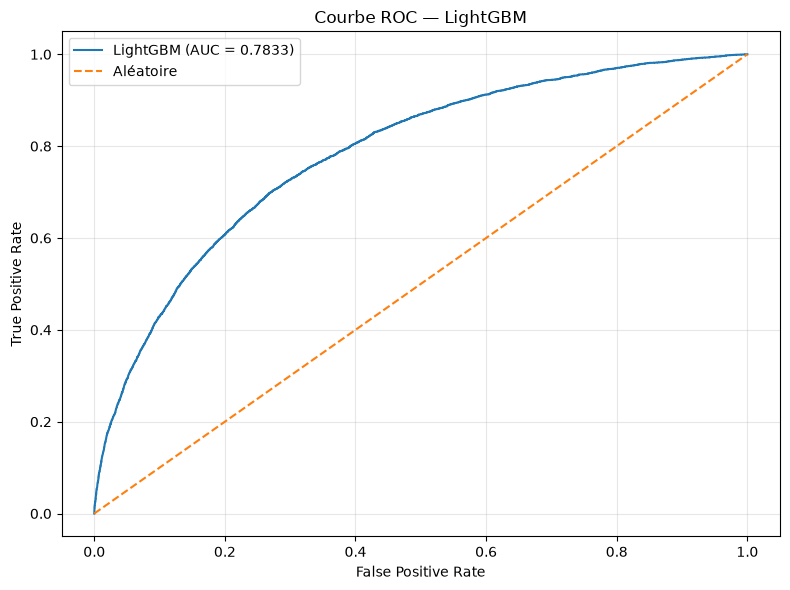

In [15]:
# ============================================================
# COURBE ROC
# ============================================================

fpr, tpr, thresholds = roc_curve(
    y_valid,
    y_proba
)

auc = roc_auc_score(
    y_valid,
    y_proba
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"LightGBM (AUC = {auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Aléatoire"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Courbe ROC — LightGBM")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "data/processed/lightgbm_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

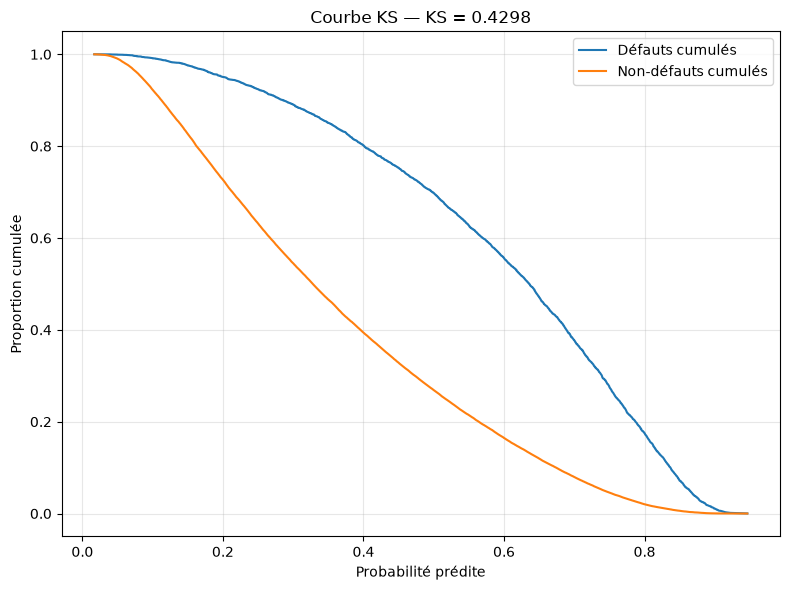

In [16]:
# ============================================================
# COURBE KS
# ============================================================

plt.figure(figsize=(8, 6))

plt.plot(
    ks_data["probability"],
    ks_data["cum_bad"],
    label="Défauts cumulés"
)

plt.plot(
    ks_data["probability"],
    ks_data["cum_good"],
    label="Non-défauts cumulés"
)

plt.xlabel("Probabilité prédite")
plt.ylabel("Proportion cumulée")
plt.title(f"Courbe KS — KS = {ks_value:.4f}")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "data/processed/lightgbm_ks_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
# ============================================================
# SAUVEGARDE DES RÉSULTATS
# ============================================================

comparison.to_csv(
    "data/processed/model_evaluation_thresholds.csv",
    index=False
)

evaluation_summary = {
    "ROC_AUC": auc,
    "KS": ks_value,
    "KS_threshold": ks_threshold,
    "Final_threshold": 0.68,
    "Final_accuracy": results_068["Accuracy"],
    "Final_precision": results_068["Precision"],
    "Final_recall": results_068["Recall"],
    "Final_F1": results_068["F1"],
    "TN": results_068["TN"],
    "FP": results_068["FP"],
    "FN": results_068["FN"],
    "TP": results_068["TP"]
}

evaluation_summary_df = pd.DataFrame(
    [evaluation_summary]
)

evaluation_summary_df.to_csv(
    "data/processed/model_final_evaluation.csv",
    index=False
)

print("✓ Résultats d'évaluation sauvegardés.")

✓ Résultats d'évaluation sauvegardés.


In [18]:
# ============================================================
# CONCLUSION
# ============================================================

print("=" * 60)
print("ÉVALUATION FINALE DU LIGHTGBM")
print("=" * 60)

print(f"ROC-AUC              : {auc:.4f}")
print(f"KS                   : {ks_value:.4f}")
print(f"Seuil final          : 0.68")
print(f"Accuracy             : {results_068['Accuracy']:.4f}")
print(f"Precision défaut     : {results_068['Precision']:.4f}")
print(f"Recall défaut        : {results_068['Recall']:.4f}")
print(f"F1-score défaut      : {results_068['F1']:.4f}")

print("\nMatrice de confusion :")
print(cm_final)

print("\n✓ Évaluation terminée.")

ÉVALUATION FINALE DU LIGHTGBM
ROC-AUC              : 0.7833
KS                   : 0.4298
Seuil final          : 0.68
Accuracy             : 0.8657
Precision défaut     : 0.2790
Recall défaut        : 0.4185
F1-score défaut      : 0.3348

Matrice de confusion :
[[51168  5370]
 [ 2887  2078]]

✓ Évaluation terminée.


In [19]:
# ============================================================
# VÉRIFICATION DES FEATURES UTILISÉES PAR LE MODÈLE
# ============================================================

print("Nombre de features :", X_valid.shape[1])

print("\nType des données :")
print(X_valid.dtypes.value_counts())

print("\nTypes uniques :")
print(X_valid.dtypes.unique())

print("\nPremières colonnes :")
print(X_valid.columns[:30].tolist())

Nombre de features : 240

Type des données :
int64      136
float64    104
Name: count, dtype: int64

Types uniques :
[dtype('int64') dtype('float64')]

Premières colonnes :
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY']


In [20]:
# ============================================================
# VÉRIFICATION DES VARIABLES CATÉGORIELLES / ENCODÉES
# ============================================================

categorical_candidates = [
    "NAME_CONTRACT_TYPE",
    "CODE_GENDER",
    "FLAG_OWN_CAR",
    "FLAG_OWN_REALTY",
    "NAME_FAMILY_STATUS",
    "NAME_EDUCATION_TYPE",
    "NAME_INCOME_TYPE",
    "NAME_HOUSING_TYPE",
    "OCCUPATION_TYPE"
]

for col in categorical_candidates:
    if col in X_valid.columns:
        print("\n" + "=" * 60)
        print(col)
        print("Type :", X_valid[col].dtype)
        print("Valeurs uniques :", X_valid[col].nunique())
        print("Valeurs :", sorted(X_valid[col].dropna().unique())[:30])


NAME_CONTRACT_TYPE
Type : int64
Valeurs uniques : 2
Valeurs : [np.int64(0), np.int64(1)]

CODE_GENDER
Type : int64
Valeurs uniques : 3
Valeurs : [np.int64(0), np.int64(1), np.int64(2)]

FLAG_OWN_CAR
Type : int64
Valeurs uniques : 2
Valeurs : [np.int64(0), np.int64(1)]

FLAG_OWN_REALTY
Type : int64
Valeurs uniques : 2
Valeurs : [np.int64(0), np.int64(1)]


In [21]:
# ============================================================
# VÉRIFICATION DES VARIABLES SHAP
# ============================================================

features_to_check = [
    "CODE_GENDER",
    "NAME_EDUCATION_TYPE_Higher_education",
    "NAME_FAMILY_STATUS_Married",
    "FLAG_OWN_CAR",
    "FLAG_OWN_REALTY"
]

for feature in features_to_check:
    print(
        feature,
        "→",
        "PRÉSENTE" if feature in X_valid.columns else "ABSENTE"
    )

CODE_GENDER → PRÉSENTE
NAME_EDUCATION_TYPE_Higher_education → ABSENTE
NAME_FAMILY_STATUS_Married → PRÉSENTE
FLAG_OWN_CAR → PRÉSENTE
FLAG_OWN_REALTY → PRÉSENTE


In [22]:
print("Valeur 365243 présente ?")
print((X_valid["DAYS_EMPLOYED"] == 365243).sum())

print("\nStatistiques :")
print(X_valid["DAYS_EMPLOYED"].describe())

print("\nValeurs les plus fréquentes :")
print(X_valid["DAYS_EMPLOYED"].value_counts().head(10))

Valeur 365243 présente ?
0

Statistiques :
count    61503.000000
mean     -2247.030942
std       2128.070234
min     -17531.000000
25%      -2754.000000
50%      -1648.000000
75%       -941.000000
max          0.000000
Name: DAYS_EMPLOYED, dtype: float64

Valeurs les plus fréquentes :
DAYS_EMPLOYED
-1648.0    11240
-213.0        36
-196.0        35
-757.0        34
-106.0        33
-201.0        32
-231.0        32
-224.0        32
-200.0        32
-193.0        32
Name: count, dtype: int64
